This test is on
1. i.i.d. rayleigh fading channel
2. 4*4 MIMO channel
3. 1000 symbols per channel
4. total of 1000 channels

ver 11.24.04.35


In [1]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 417, done.
remote: Counting objects: 100% (417/417), done.
remote: Compressing objects: 100% (298/298), done.
remote: Total 417 (delta 181), reused 272 (delta 100), pack-reused 0 (from 0)
Receiving objects: 100% (417/417), 7.72 MiB | 14.06 MiB/s, done.
Resolving deltas: 100% (181/181), done.
/content/EE_MIMO_PROJECT
NYCU_scene  requirements.txt  simulation_results  src


In [2]:
# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

In [6]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 1000
SYMBOLS_PER_CHANNEL = 100
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 4
NR = 4
SNR_DB = list(range(0, 21, 2))

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
symbol_qpsk = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])
bpsk = torch.tensor([-1, 1], dtype=torch.complex128) / 2**0.5
symbol_bpsk = torch.tensor([[0], [1]])

In [7]:
import inspect

print(inspect.getfile(partialMAP))
print(inspect.signature(partialMAP))

/content/EE_MIMO_PROJECT/src/models/partialMAP.py
(*, verbose=True, csv_log_dir=None)


running channel number 0
running channel number 10
running channel number 20
running channel number 30
running channel number 40
running channel number 50
running channel number 60
running channel number 70
running channel number 80
running channel number 90
running channel number 100
running channel number 110
running channel number 120
running channel number 130
running channel number 140
running channel number 150
running channel number 160
running channel number 170
running channel number 180
running channel number 190
running channel number 200
running channel number 210
running channel number 220
running channel number 230
running channel number 240
running channel number 250
running channel number 260
running channel number 270
running channel number 280
running channel number 290
running channel number 300
running channel number 310
running channel number 320
running channel number 330
running channel number 340
running channel number 350
running channel number 360
running chan

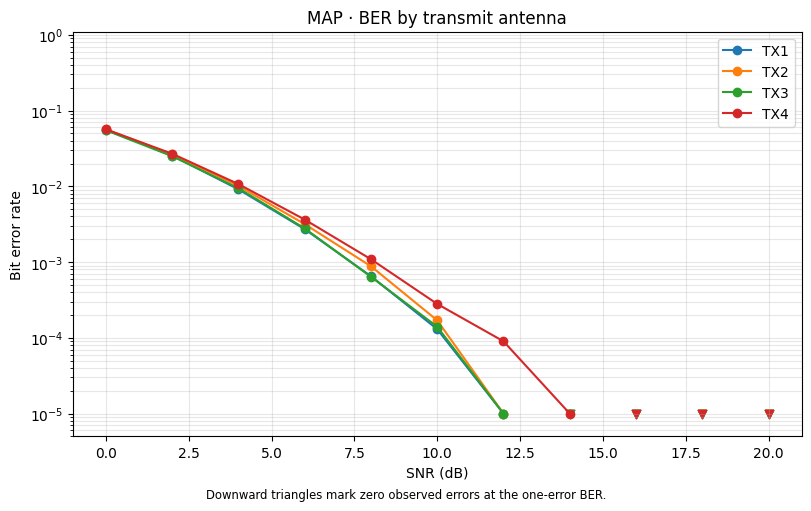

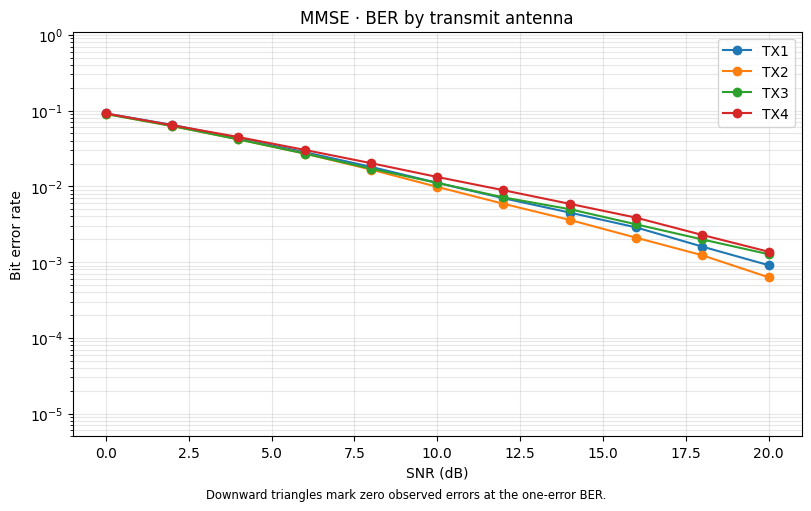

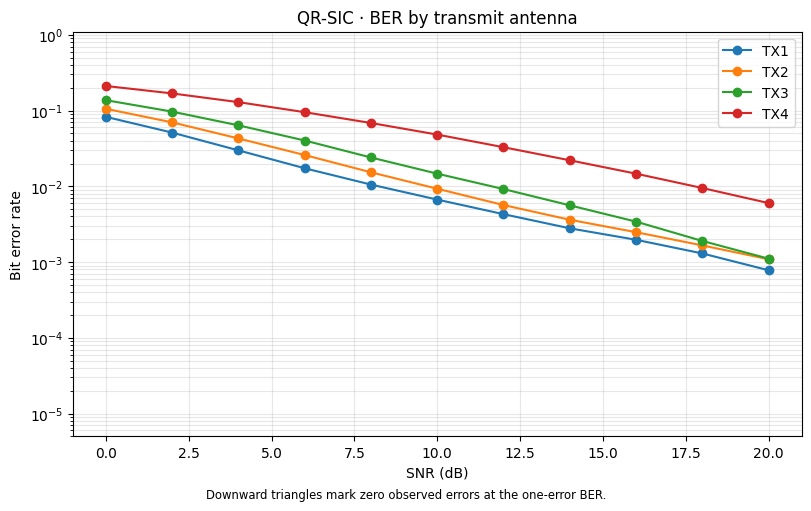

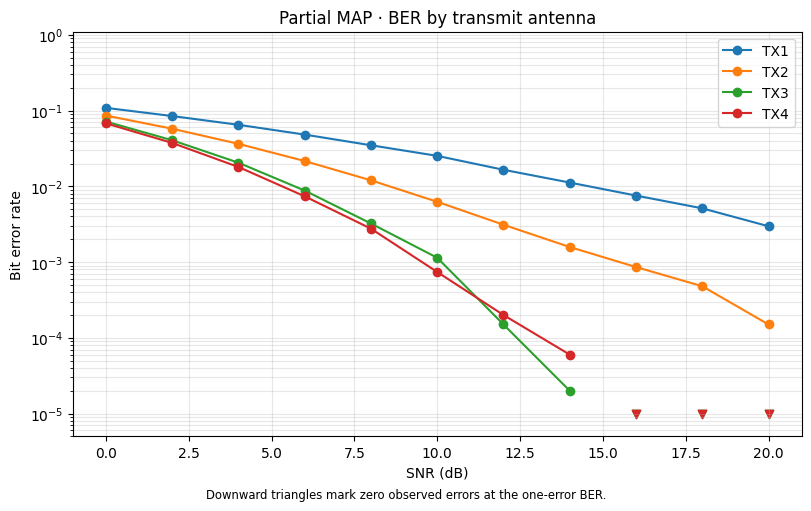

400,000 bits per SNR
SNR (dB)            MAP          MMSE        QR-SIC   Partial MAP
       0        0.05601       0.09092        0.1341        0.0835
       2        0.02593       0.06345       0.09653       0.05503
       4        0.00985       0.04281       0.06641       0.03494
       6       0.003077       0.02816       0.04465       0.02148
       8       0.000815         0.018        0.0296        0.0132
      10        0.00018       0.01133       0.01971      0.008342
      12          3e-05      0.007215       0.01299      0.004998
      14        2.5e-06       0.00474       0.00852      0.003217
      16              0      0.002995       0.00564      0.002103
      18              0      0.001775       0.00359        0.0014
      20              0      0.001045      0.002247       0.00078


In [8]:
from pathlib import Path
from tempfile import mkdtemp

from src.channel.testbench import Testbench

# Use a fresh directory because Partial MAP appends rows to its CSV files.
pmap_log_dir = Path(mkdtemp(prefix="rayleigh_pmap_"))
models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False, csv_log_dir=pmap_log_dir),
}

bench = Testbench(models, bpsk, symbol_bpsk, SYMBOLS_PER_CHANNEL, SNR_DB)
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
ERROR_CSV = "rayleigh_bit_errors.csv"
ber, bits_per_snr = bench.run(csi, csv_path=ERROR_CSV, plot_antenna_ber=True)

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

In [11]:
# Download all Partial MAP layer CSVs together.
from zipfile import ZIP_DEFLATED, ZipFile

archive_path = pmap_log_dir / "rayleigh_pmap_layers.zip"
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for layer in range(NT):
        layer_csv = pmap_log_dir / f"layer_{layer}.csv"
        archive.write(layer_csv, arcname=layer_csv.name)

try:
    from google.colab import files
except ImportError:
    print(f"Saved Partial MAP CSV archive to {archive_path}")
else:
    files.download(str(archive_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Save all Partial MAP layer CSVs as a zip directly to Google Drive root.
import shutil
from zipfile import ZIP_DEFLATED, ZipFile

from google.colab import drive

drive.mount("/content/drive")

archive_path = pmap_log_dir / "rayleigh_pmap_layers.zip"
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for layer in range(NT):
        layer_csv = pmap_log_dir / f"layer_{layer}.csv"
        archive.write(layer_csv, arcname=layer_csv.name)

drive_path = "/content/drive/MyDrive/rayleigh_pmap_layers.zip"
shutil.copy(archive_path, drive_path)
print(f"Saved Partial MAP CSV archive to {drive_path}")

Mounted at /content/drive
Saved Partial MAP CSV archive to /content/drive/MyDrive/rayleigh_pmap_layers.zip


Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

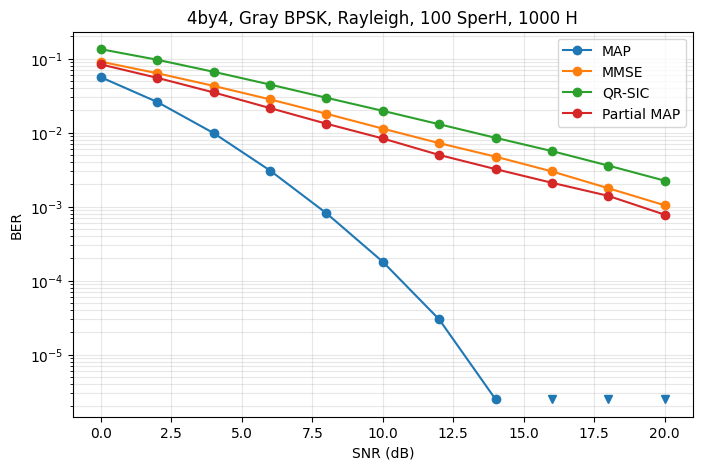

In [10]:
import matplotlib.pyplot as plt
import numpy as np

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray BPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(ERROR_CSV)
    files.download(f'{TITLE}.png')

plt.show()